In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")



Libraries imported successfully!


In [2]:

np.random.seed(42)

n = 1000

df = pd.DataFrame({
    "Temperature": np.random.normal(70, 10, n),
    "Vibration": np.random.normal(5, 2, n),
    "Pressure": np.random.normal(30, 5, n),
    "Runtime_Hours": np.random.randint(100, 5000, n)
})

df["Failure"] = (
    (df["Temperature"] > 85) |
    (df["Vibration"] > 8) |
    (df["Pressure"] > 38)
).astype(int)

print(df.head())
print("\nDataset shape:", df.shape)
print("\nFailure counts:")
print(df["Failure"].value_counts())


   Temperature  Vibration   Pressure  Runtime_Hours  Failure
0    74.967142   7.798711  26.624109            831        0
1    68.617357   6.849267  29.277407           4061        0
2    76.476885   5.119261  26.037900           4801        0
3    85.230299   3.706126  28.460192           2604        1
4    67.658466   6.396447  20.531927            714        0

Dataset shape: (1000, 5)

Failure counts:
Failure
0    806
1    194
Name: count, dtype: int64


In [3]:

X = df[[
    "Temperature",
    "Vibration",
    "Pressure",
    "Runtime_Hours"
]]

y = df["Failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Model Accuracy: 99.5 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       161
           1       0.97      1.00      0.99        39

    accuracy                           0.99       200
   macro avg       0.99      1.00      0.99       200
weighted avg       1.00      0.99      1.00       200



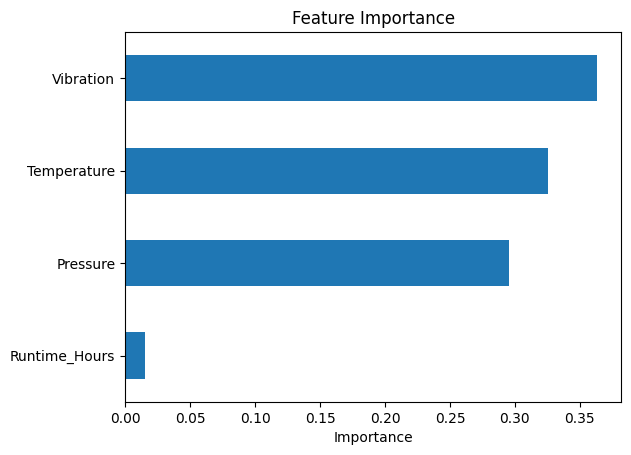

In [4]:

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot(kind="barh", title="Feature Importance")
plt.xlabel("Importance")
plt.show()


In [5]:

new_machine = pd.DataFrame([{
    "Temperature": 90,
    "Vibration": 9,
    "Pressure": 40,
    "Runtime_Hours": 4000
}])

prediction = model.predict(new_machine)[0]

if prediction == 1:
    print("Prediction: Potential machine failure detected.")
else:
    print("Prediction: No failure predicted.")

print("Note: This is a demonstration model using synthetic data.")


Prediction: Potential machine failure detected.
Note: This is a demonstration model using synthetic data.
